In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score,
                             RocCurveDisplay)

RANDOM_STATE = 42
data = load_breast_cancer(as_frame=True)
X = data.data.copy()
# scikit-learn encodes malignant as 0 and benign as 1; invert for malignant-positive analysis
y = (data.target == 0).astype(int)
df = X.copy()
df["diagnosis"] = y.map({0: "Benign", 1: "Malignant"})
print("Shape:", df.shape)
print("Features:", X.shape[1])
print(df.head())

Shape: (569, 31)
Features: 30
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter

In [2]:
print("Dataset shape:", X.shape)
print("\\nTarget counts (0=Benign, 1=Malignant):")
print(y.value_counts().sort_index())
print("\\nTarget percentages:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))
print("\\nData types:")
print(X.dtypes.value_counts())
print("\\nMissing values:", int(X.isna().sum().sum()))
print("Duplicate rows:", int(X.duplicated().sum()))
print("\\nDescriptive statistics:")
display(X.describe().T)

Dataset shape: (569, 30)
\nTarget counts (0=Benign, 1=Malignant):
target
0    357
1    212
Name: count, dtype: int64
\nTarget percentages:
target
0    62.74
1    37.26
Name: proportion, dtype: float64
\nData types:
float64    30
Name: count, dtype: int64
\nMissing values: 0
Duplicate rows: 0
\nDescriptive statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


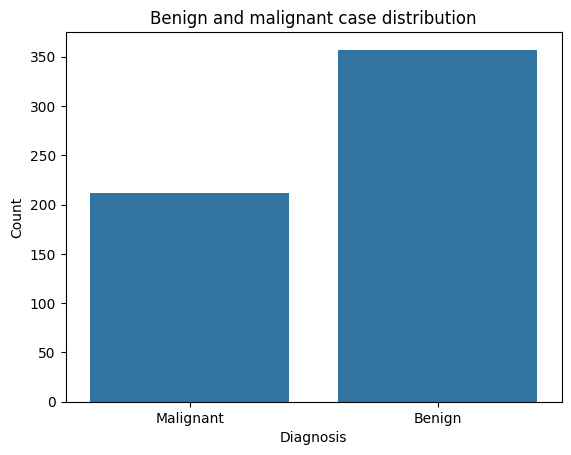

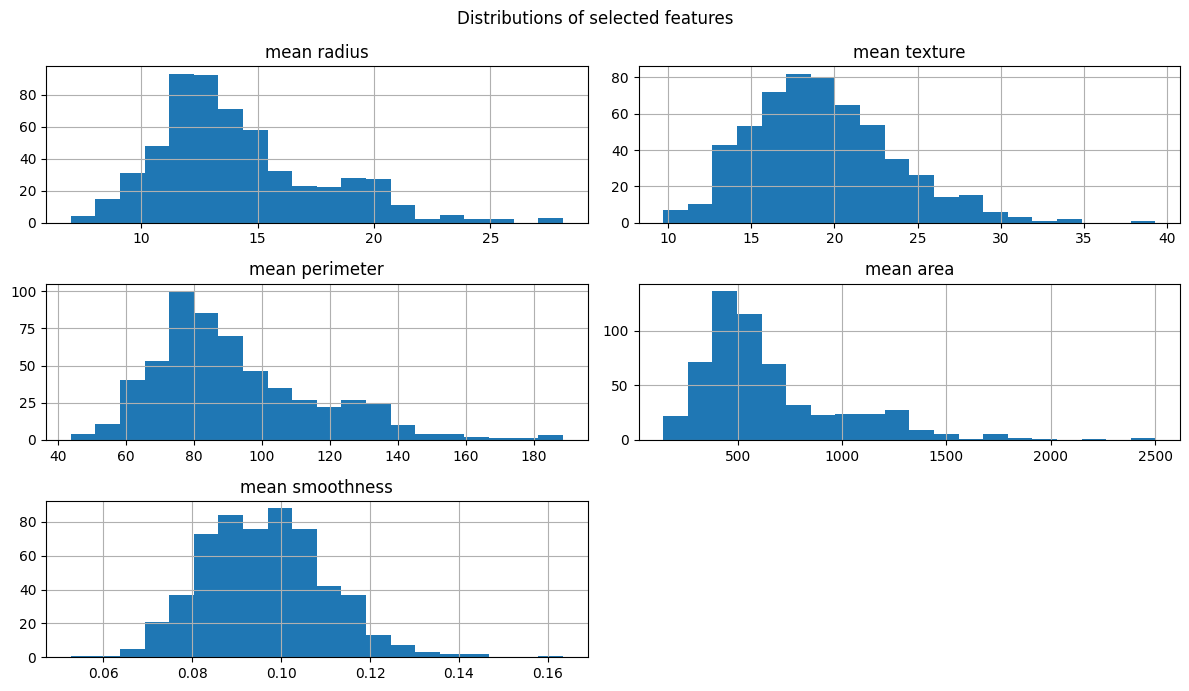

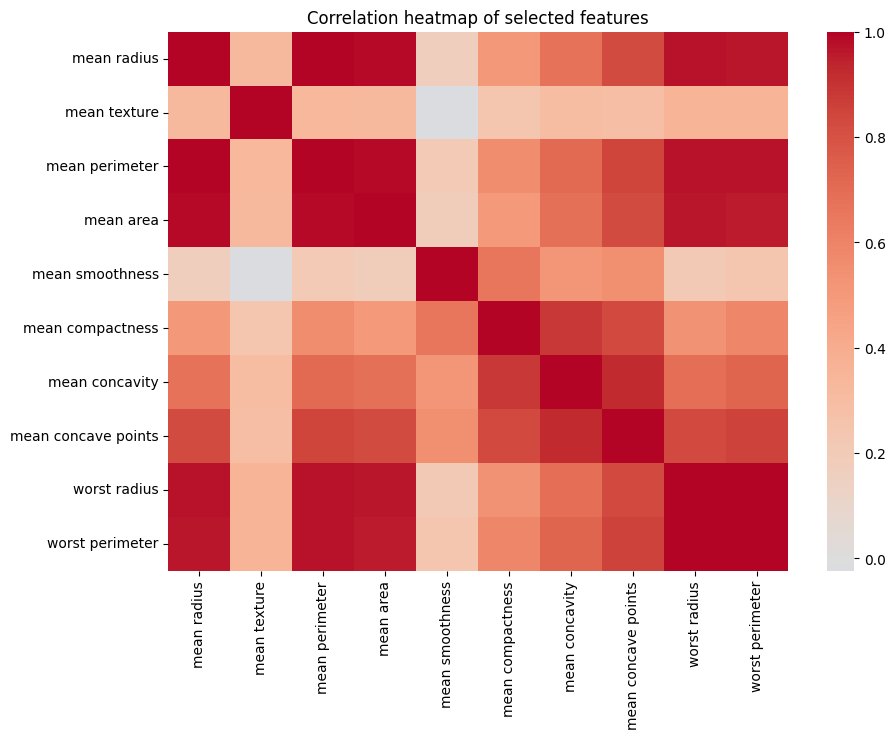

           mean radius  mean texture  mean perimeter  mean area  \
diagnosis                                                         
Benign          12.147        17.915          78.075    462.790   
Malignant       17.463        21.605         115.365    978.376   

           mean smoothness  
diagnosis                   
Benign               0.092  
Malignant            0.103  


In [3]:
# Class distribution
sns.countplot(x=df["diagnosis"])
plt.title("Benign and malignant case distribution")
plt.xlabel("Diagnosis"); plt.ylabel("Count"); plt.show()

# Feature distributions for selected measurements
selected = ["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness"]
df[selected].hist(figsize=(12, 7), bins=20)
plt.suptitle("Distributions of selected features")
plt.tight_layout(); plt.show()

# Correlation heatmap for a manageable subset
corr_features = ["mean radius", "mean texture", "mean perimeter", "mean area",
                 "mean smoothness", "mean compactness", "mean concavity",
                 "mean concave points", "worst radius", "worst perimeter"]
plt.figure(figsize=(10, 7))
sns.heatmap(df[corr_features].corr(), cmap="coolwarm", center=0)
plt.title("Correlation heatmap of selected features")
plt.show()

# Compare selected measurements by diagnosis
print(df.groupby("diagnosis")[selected].mean().round(3))

In [4]:
# IQR outlier counts for each feature (descriptive check; observations are not automatically removed)
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outlier_counts = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()
print("Features with the most IQR-flagged values:")
display(outlier_counts.sort_values(ascending=False).head(10).to_frame("IQR outlier count"))

Features with the most IQR-flagged values:


,IQR outlier count
area error,65
radius error,38
perimeter error,38
worst area,35
smoothness error,30
fractal dimension error,28
compactness error,28
symmetry error,27
mean area,25
worst fractal dimension,24


In [5]:
# The target is already binary encoded: benign=0, malignant=1.
# Standardization is placed inside pipelines for models sensitive to feature scale.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))
print("Testing class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training rows: 398
Testing rows: 171
Training class proportions:
target
0    0.628
1    0.372
Name: proportion, dtype: float64
Testing class proportions:
target
0    0.626
1    0.374
Name: proportion, dtype: float64


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.9708,0.9836,0.9375,0.9600,0.9975
Decision Tree,0.9006,0.8852,0.8438,0.8640,0.8892
KNN,0.9649,1.0000,0.9062,0.9508,0.9882


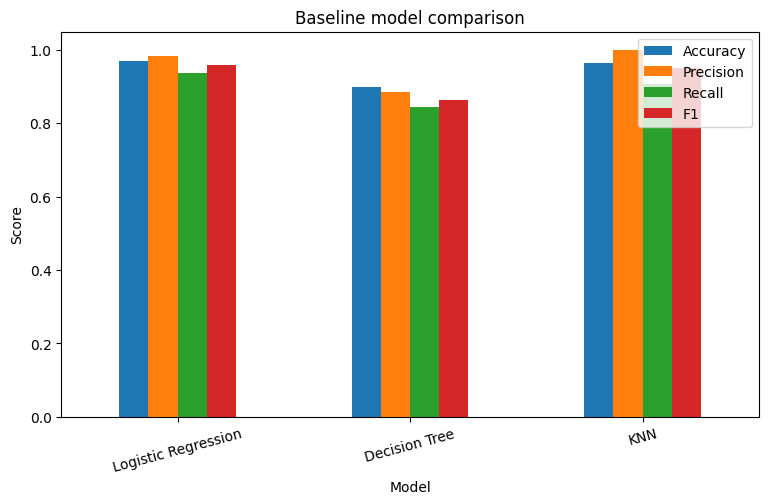

In [6]:
baseline_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])
}

baseline_results = []
for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

baseline_df = pd.DataFrame(baseline_results).set_index("Model")
display(baseline_df.round(4))
baseline_df[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", ylim=(0, 1.05), figsize=(9, 5))
plt.title("Baseline model comparison"); plt.ylabel("Score"); plt.xticks(rotation=15); plt.show()

In [7]:
# Use class_weight='balanced' for Logistic Regression and Random Forest.
# This gives the minority malignant class more weight during training.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grids = {
    "Logistic Regression (tuned)": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE,
                                         class_weight="balanced"))
        ]),
        {"model__C": [0.1, 1, 10]}
    ),
    "Random Forest (tuned)": (
        RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
        {"n_estimators": [200, 300],
         "max_depth": [None, 5, 10],
         "min_samples_split": [2, 5]}
    ),
    "Gradient Boosting (tuned)": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {"n_estimators": [100, 150],
         "learning_rate": [0.05, 0.1],
         "max_depth": [2, 3]}
    )
}

tuned_models = {}
tuned_results = []
for name, (estimator, param_grid) in param_grids.items():
    search = GridSearchCV(estimator, param_grid, scoring="f1", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    model = search.best_estimator_
    tuned_models[name] = model
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    tuned_results.append({
        "Model": name,
        "CV best F1": search.best_score_,
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Precision": precision_score(y_test, pred),
        "Test Recall": recall_score(y_test, pred),
        "Test F1": f1_score(y_test, pred),
        "Test ROC-AUC": roc_auc_score(y_test, prob),
        "Best parameters": search.best_params_
    })

tuned_df = pd.DataFrame(tuned_results).set_index("Model")
display(tuned_df.round(4))

,CV best F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Best parameters
Model,,,,,,,
Logistic Regression (tuned),0.9590,0.9883,1.0,0.9688,0.9841,0.9988,{'model__C': 0.1}
Random Forest (tuned),0.9227,0.9766,1.0,0.9375,0.9677,0.9975,"{'max_depth': None, 'min_samples_split': 5, 'n..."
Gradient Boosting (tuned),0.9241,0.9708,1.0,0.9219,0.9593,0.9965,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."


Selected model: Logistic Regression (tuned)
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99       107
   Malignant       1.00      0.97      0.98        64

    accuracy                           0.99       171
   macro avg       0.99      0.98      0.99       171
weighted avg       0.99      0.99      0.99       171

Confusion matrix (rows=actual, columns=predicted):
[[107   0]
 [  2  62]]


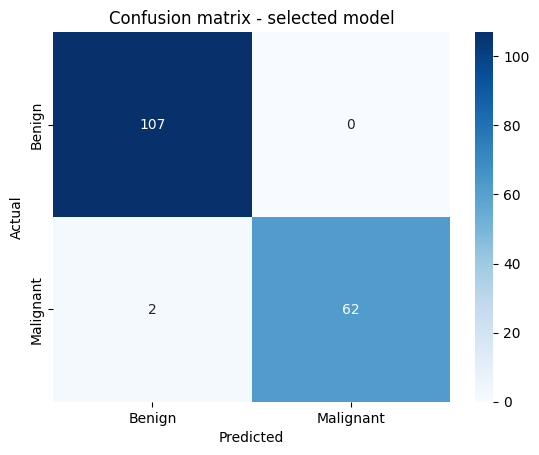

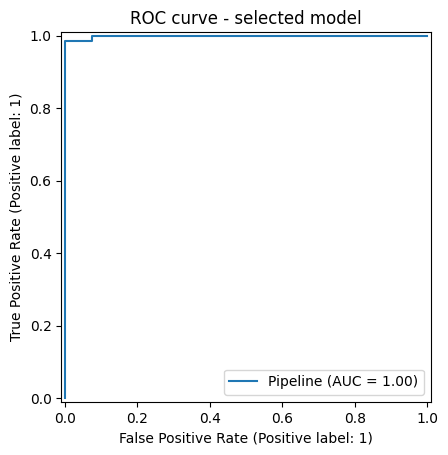

Test ROC-AUC: 0.9988


In [8]:
# Select the model with the highest cross-validated F1 score.
best_name = tuned_df["CV best F1"].idxmax()
best_model = tuned_models[best_name]
print("Selected model:", best_name)

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))
print("Confusion matrix (rows=actual, columns=predicted):")
cm = confusion_matrix(y_test, y_pred)
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Benign", "Malignant"],
            yticklabels=["Benign", "Malignant"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion matrix - selected model"); plt.show()

RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title("ROC curve - selected model"); plt.show()

print("Test ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

,Importance
worst perimeter,0.147008
worst area,0.140579
mean concave points,0.114108
worst concave points,0.091467
worst radius,0.071460
mean radius,0.057945
mean perimeter,0.048893
mean concavity,0.048820
mean area,0.040022
worst concavity,0.038438


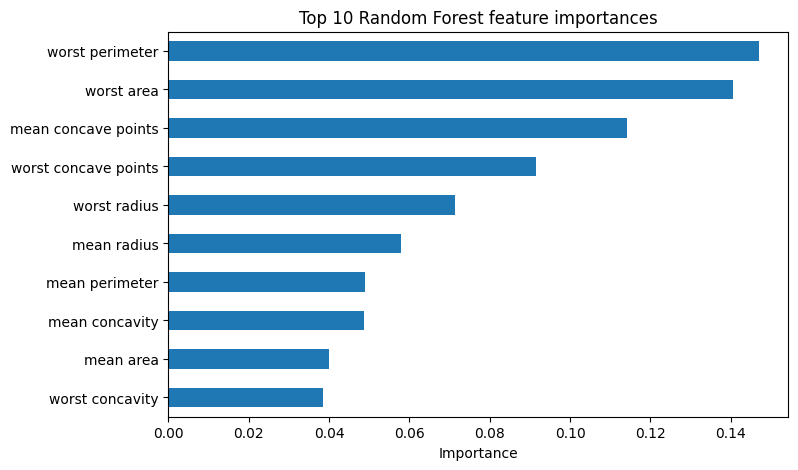

In [9]:
# Random Forest impurity-based feature importance
rf_model = tuned_models["Random Forest (tuned)"]
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
display(importance.head(10).to_frame("Importance"))
importance.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Random Forest feature importances")
plt.xlabel("Importance"); plt.show()

In [10]:
print("Selected model:", best_name)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

Selected model: Logistic Regression (tuned)
Accuracy: 0.9883
Precision: 1.0
Recall: 0.9688
F1: 0.9841
ROC-AUC: 0.9988
